In [5]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import sys
sys.path.append('/media/dll-1/SSD 4TB/code/LEEDNet/')  # Replace with real path
from EEGDataLoader import EEGDataset
from models.LEEDNetModel import LEEDNetModel
import config as config

model_saving_name = "/media/dll-1/SSD 4TB/EEG Datasets/experiment/nouman_conv_2/model/weights/conv_tt_12_tukl.pt"

epochs = 30
batch_size = 64
hidden_size = 20
output_size = 3  # Binary classification
number_of_eeg_channels = 1
eval_batch = 1
threshold = 0.495
active_branches = [1,2]

In [3]:
train_dataset = EEGDataset(config.train_data_csv, number_of_eeg_channels=number_of_eeg_channels)
val_dataset = EEGDataset(config.val_data_csv, number_of_eeg_channels=number_of_eeg_channels)
test_dataset = EEGDataset(config.test_data_csv, number_of_eeg_channels=number_of_eeg_channels)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)#, collate_fn=collate)
val_loader = DataLoader(val_dataset, batch_size=eval_batch, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=eval_batch, shuffle=False)

In [ ]:
input = train_dataset.__getitem__(0)
input_x1 = input[1].shape
input_x2 = input[2].shape
input_x3 = input[3].shape
criterion = nn.CrossEntropyLoss()

loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

print(input_x1,input_x2,input_x3)
input_channels_list = [input_x1[1], input_x2[1], input_x3[1]]

model = LEEDNetModel(input_channels_list=input_channels_list, output_size=3)

main_output, aux_outputs = model([input[1], input[2], input[3]], active_branch_indices=active_branches)
print("Output shape:", main_output.shape) 

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001,betas=(0.9, 0.98), eps=1e-9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

torch.Size([1, 1, 400]) torch.Size([1, 33, 14]) torch.Size([1, 30, 400])
Output shape: torch.Size([1, 3])


/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


ConvParallelEEG1DModel(
  (branches): ModuleList(
    (0): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(in_features=32, out_features=3, bias=True)
    )
    (1): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(33, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(

In [4]:
# prev_eval_loss = 0
# prev_eval_acc = 0


In [5]:
# model = model.to(device)

# prev_eval_loss, prev_eval_acc = eval(model, val_loader, loss_fn, 1,False,'', active_branches, device)
# print("Loss:",prev_eval_loss, "Accuracy",prev_eval_acc)

/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:56: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


Step 0/43343
Step 100/43343
Step 200/43343
Step 300/43343
Step 400/43343
Step 500/43343
Step 600/43343
Step 700/43343
Step 800/43343
Step 900/43343
Step 1000/43343
Step 1100/43343
Step 1200/43343
Step 1300/43343
Step 1400/43343
Step 1500/43343
Step 1600/43343
Step 1700/43343
Step 1800/43343
Step 1900/43343
Step 2000/43343
Step 2100/43343
Step 2200/43343
Step 2300/43343
Step 2400/43343
Step 2500/43343
Step 2600/43343
Step 2700/43343
Step 2800/43343
Step 2900/43343
Step 3000/43343
Step 3100/43343
Step 3200/43343
Step 3300/43343
Step 3400/43343
Step 3500/43343
Step 3600/43343
Step 3700/43343
Step 3800/43343
Step 3900/43343
Step 4000/43343
Step 4100/43343
Step 4200/43343
Step 4300/43343
Step 4400/43343
Step 4500/43343
Step 4600/43343
Step 4700/43343
Step 4800/43343
Step 4900/43343
Step 5000/43343
Step 5100/43343
Step 5200/43343
Step 5300/43343
Step 5400/43343
Step 5500/43343
Step 5600/43343
Step 5700/43343
Step 5800/43343
Step 5900/43343
Step 6000/43343
Step 6100/43343
Step 6200/43343
Step

/home/anaconda/anaconda3/envs/braindecode/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [6]:
# result = {"epoch":[],"train_loss":[],"train_acc":[],"eval_loss":[],"eval_acc":[],"test_acc":[],"test_loss":[]}
# saved_epoch = 0

In [7]:
# for epoch in range(epochs):  # loop over the dataset multiple times
#     train_loss, train_acc = train(model, train_loader,optimizer, loss_fn, active_branches, device)
#     print(f"Train Loss after epoch {epoch+2}: {train_loss} Train ACC after epoch {epoch}: {train_acc}")
#     eval_loss, eval_acc = eval(model, test_loader, loss_fn, eval_batch,False,'', active_branches, device)
#     print(f"VAL Loss after epoch {epoch}: {eval_loss} VAL ACC after epoch {epoch}: {eval_acc}")
#     # test_loss, test_acc = eval(model, test_loader, loss_fn, eval_batch,False,'', active_branches, device)
#     test_loss = eval_loss
#     test_acc = eval_acc
#     print(f"Test Loss after epoch {epoch}: {test_loss} Test Acc after epoch {epoch}: {test_acc}")

#     scheduler.step(eval_loss)
    
#     result['epoch'].append(epoch)
    
#     result['train_loss'].append(train_loss)
#     result['train_acc'].append(train_acc)
#     result['eval_loss'].append(eval_loss)
#     result['eval_acc'].append(eval_acc)
#     result['test_loss'].append(test_loss)
#     result['test_acc'].append(test_acc)

#     if prev_eval_acc < eval_acc:
#       prev_eval_acc = eval_acc
#       saved_epoch = epoch
#       torch.save(model.state_dict(), model_saving_name)
#       print("WEIGHTS SAVED")

/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:56: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


Step 0/4531
Step 100/4531
Step 200/4531
Step 300/4531
Step 400/4531
Step 500/4531
Step 600/4531
Step 700/4531
Step 800/4531
Step 900/4531
Step 1000/4531
Step 1100/4531
Step 1200/4531
Step 1300/4531
Step 1400/4531
Step 1500/4531
Step 1600/4531
Step 1700/4531
Step 1800/4531
Step 1900/4531
Step 2000/4531
Step 2100/4531
Step 2200/4531
Step 2300/4531
Step 2400/4531
Step 2500/4531
Step 2600/4531
Step 2700/4531
Step 2800/4531
Step 2900/4531
Step 3000/4531
Step 3100/4531
Step 3200/4531
Step 3300/4531
Step 3400/4531
Step 3500/4531
Step 3600/4531
Step 3700/4531
Step 3800/4531
Step 3900/4531
Step 4000/4531
Step 4100/4531
Step 4200/4531
Step 4300/4531
Step 4400/4531
Step 4500/4531
Correct Classified: 200007.0 / 289972
Class-wise correct: Class 0 = 125826.0, Class 1 = 30691.0, Class 2 = 43490.0
Train Loss after epoch 2: 0.8131607206839648 Train ACC after epoch 0: 0.6897459065013174
Step 0/74774


/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:56: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


Step 100/74774
Step 200/74774
Step 300/74774
Step 400/74774
Step 500/74774
Step 600/74774
Step 700/74774
Step 800/74774
Step 900/74774
Step 1000/74774
Step 1100/74774
Step 1200/74774
Step 1300/74774
Step 1400/74774
Step 1500/74774
Step 1600/74774
Step 1700/74774
Step 1800/74774
Step 1900/74774
Step 2000/74774
Step 2100/74774
Step 2200/74774
Step 2300/74774
Step 2400/74774
Step 2500/74774
Step 2600/74774
Step 2700/74774
Step 2800/74774
Step 2900/74774
Step 3000/74774
Step 3100/74774
Step 3200/74774
Step 3300/74774
Step 3400/74774
Step 3500/74774
Step 3600/74774
Step 3700/74774
Step 3800/74774
Step 3900/74774
Step 4000/74774
Step 4100/74774
Step 4200/74774
Step 4300/74774
Step 4400/74774
Step 4500/74774
Step 4600/74774
Step 4700/74774
Step 4800/74774
Step 4900/74774
Step 5000/74774
Step 5100/74774
Step 5200/74774
Step 5300/74774
Step 5400/74774
Step 5500/74774
Step 5600/74774
Step 5700/74774
Step 5800/74774
Step 5900/74774
Step 6000/74774
Step 6100/74774
Step 6200/74774
Step 6300/74774
S

/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:56: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


...

Step 100/74774
Step 200/74774
Step 300/74774
Step 400/74774
Step 500/74774
Step 600/74774
Step 700/74774
Step 800/74774
Step 900/74774
Step 1000/74774
Step 1100/74774
Step 1200/74774
Step 1300/74774
Step 1400/74774
Step 1500/74774
Step 1600/74774
Step 1700/74774
Step 1800/74774
Step 1900/74774
Step 2000/74774
Step 2100/74774
Step 2200/74774
Step 2300/74774
Step 2400/74774
Step 2500/74774
Step 2600/74774
Step 2700/74774
Step 2800/74774
Step 2900/74774
Step 3000/74774
Step 3100/74774
Step 3200/74774
Step 3300/74774
Step 3400/74774
Step 3500/74774
Step 3600/74774
Step 3700/74774
Step 3800/74774
Step 3900/74774
Step 4000/74774
Step 4100/74774
Step 4200/74774
Step 4300/74774
Step 4400/74774
Step 4500/74774
Step 4600/74774
Step 4700/74774
Step 4800/74774
Step 4900/74774
Step 5000/74774
Step 5100/74774
Step 5200/74774
Step 5300/74774
Step 5400/74774
Step 5500/74774
Step 5600/74774
Step 5700/74774
Step 5800/74774
Step 5900/74774
Step 6000/74774
Step 6100/74774
Step 6200/74774
Step 6300/74774
S

/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:56: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


Step 100/4531
Step 200/4531
Step 300/4531
Step 400/4531
Step 500/4531
Step 600/4531
Step 700/4531
Step 800/4531
Step 900/4531
Step 1000/4531
Step 1100/4531
Step 1200/4531
Step 1300/4531
Step 1400/4531
Step 1500/4531
Step 1600/4531
Step 1700/4531
Step 1800/4531
Step 1900/4531
Step 2000/4531
Step 2100/4531
Step 2200/4531
Step 2300/4531
Step 2400/4531
Step 2500/4531
Step 2600/4531
Step 2700/4531
Step 2800/4531
Step 2900/4531
Step 3000/4531
Step 3100/4531
Step 3200/4531
Step 3300/4531
Step 3400/4531
Step 3500/4531
Step 3600/4531
Step 3700/4531
Step 3800/4531
Step 3900/4531
Step 4000/4531
Step 4100/4531
Step 4200/4531
Step 4300/4531
Step 4400/4531
Step 4500/4531
Correct Classified: 233043.0 / 289972
Class-wise correct: Class 0 = 124691.0, Class 1 = 41458.0, Class 2 = 66894.0
Train Loss after epoch 31: 0.6535969602959069 Train ACC after epoch 29: 0.8036741478487578
Step 0/74774


/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:56: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


Step 100/74774
Step 200/74774
Step 300/74774
Step 400/74774
Step 500/74774
Step 600/74774
Step 700/74774
Step 800/74774
Step 900/74774
Step 1000/74774
Step 1100/74774
Step 1200/74774
Step 1300/74774
Step 1400/74774
Step 1500/74774
Step 1600/74774
Step 1700/74774
Step 1800/74774
Step 1900/74774
Step 2000/74774
Step 2100/74774
Step 2200/74774
Step 2300/74774
Step 2400/74774
Step 2500/74774
Step 2600/74774
Step 2700/74774
Step 2800/74774
Step 2900/74774
Step 3000/74774
Step 3100/74774
Step 3200/74774
Step 3300/74774
Step 3400/74774
Step 3500/74774
Step 3600/74774
Step 3700/74774
Step 3800/74774
Step 3900/74774
Step 4000/74774
Step 4100/74774
Step 4200/74774
Step 4300/74774
Step 4400/74774
Step 4500/74774
Step 4600/74774
Step 4700/74774
Step 4800/74774
Step 4900/74774
Step 5000/74774
Step 5100/74774
Step 5200/74774
Step 5300/74774
Step 5400/74774
Step 5500/74774
Step 5600/74774
Step 5700/74774
Step 5800/74774
Step 5900/74774
Step 6000/74774
Step 6100/74774
Step 6200/74774
Step 6300/74774
S

In [8]:
# print("Epoch | Train Loss | Train Acc | Eval Loss | Eval Acc | Test Loss | Test Acc  ")
# for epoch in range(epochs):
#     if(saved_epoch == epoch):
#         print("Saved Weights")
#     print(result['epoch'][epoch],"|",result['train_loss'][epoch],"|",result['train_acc'][epoch],"|",result['eval_loss'][epoch],"|",result['eval_acc'][epoch],"|",result['test_loss'][epoch],"|",result['test_acc'][epoch])

Epoch | Train Loss | Train Acc | Eval Loss | Eval Acc | Test Loss | Test Acc  
0 | 0.8131607206839648 | 0.6897459065013174 | 0.7341902548427373 | 0.7166929681440073 | 0.7341902548427373 | 0.7166929681440073
1 | 0.7300113166333613 | 0.7563454402494034 | 0.7178821404234795 | 0.7499531922860887 | 0.7178821404234795 | 0.7499531922860887
2 | 0.7112012991866274 | 0.7683638420261266 | 0.7128754002771116 | 0.7573755583491588 | 0.7128754002771116 | 0.7573755583491588
3 | 0.7000422561781687 | 0.7738229898059122 | 0.705143888243242 | 0.7562387995827426 | 0.705143888243242 | 0.7562387995827426
Saved Weights
4 | 0.6912636334757699 | 0.7796614845571297 | 0.7082605194624746 | 0.7583919544226603 | 0.7082605194624746 | 0.7583919544226603
5 | 0.6849802914333512 | 0.7836687680189811 | 0.700463095622137 | 0.7414074410891487 | 0.700463095622137 | 0.7414074410891487
6 | 0.6801854040390659 | 0.7869208061468004 | 0.7031713268392865 | 0.7455398935458849 | 0.7031713268392865 | 0.7455398935458849
7 | 0.676689203

In [11]:
model_state_dict = torch.load(model_saving_name)
# Load the state_dict into the model
model.load_state_dict(model_state_dict)
# eval_loss, eval_acc = eval(model, val_loader, loss_fn, eval_batch,True,prediction_saving_csv_eval, active_branches, device)
# print(f"VAL Loss: {eval_loss} VAL ACC: {eval_acc}")

# eval_loss, eval_acc = eval(model, train_loader, loss_fn, eval_batch,True,prediction_saving_csv_train)
# print(f"Train Loss: {eval_loss} Train ACC: {eval_acc}")

/tmp/ipykernel_116383/2470549735.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_state_dict = torch.load(model_saving_name)


<All keys matched successfully>


Running model on a subset of test data to collect features for t-SNE...



Collected features from 74774 samples.

Running t-SNE for: FFT Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Wavelet Branch...
(74774, 32)
(74774,)


KeyboardInterrupt: 

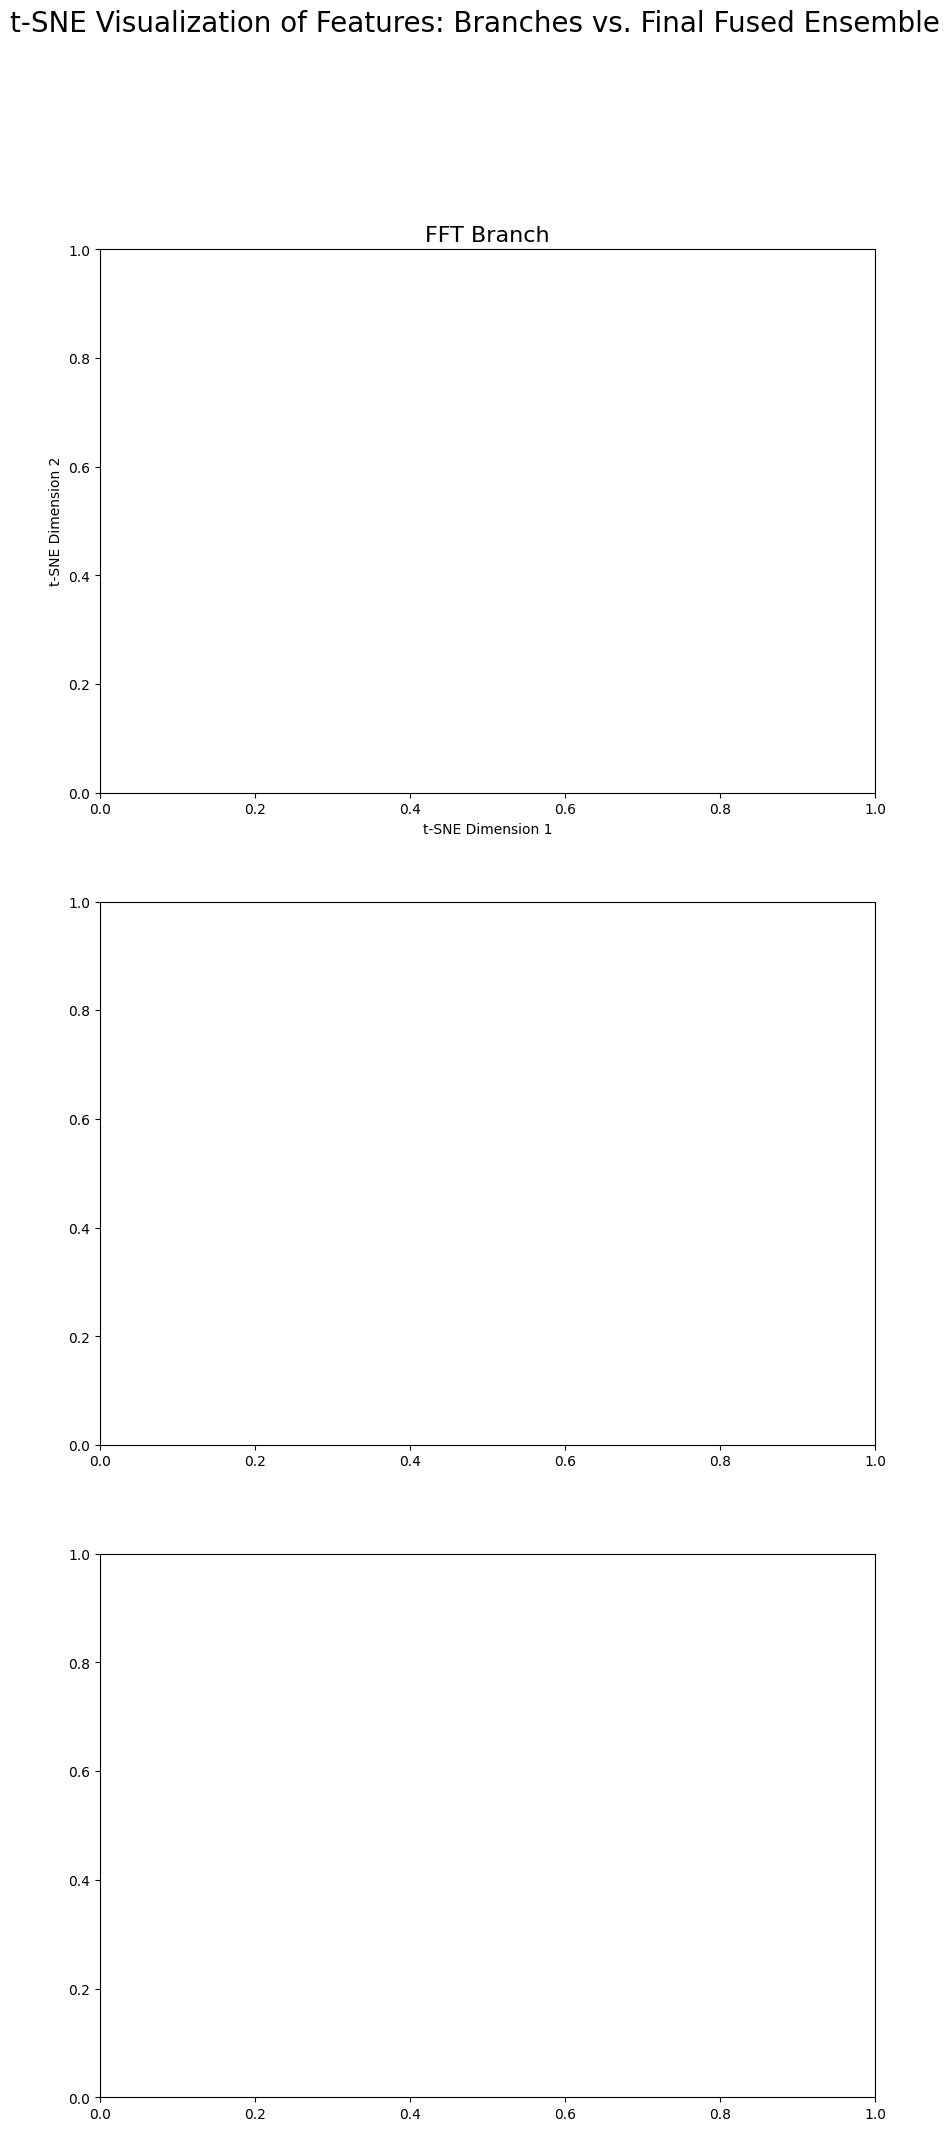

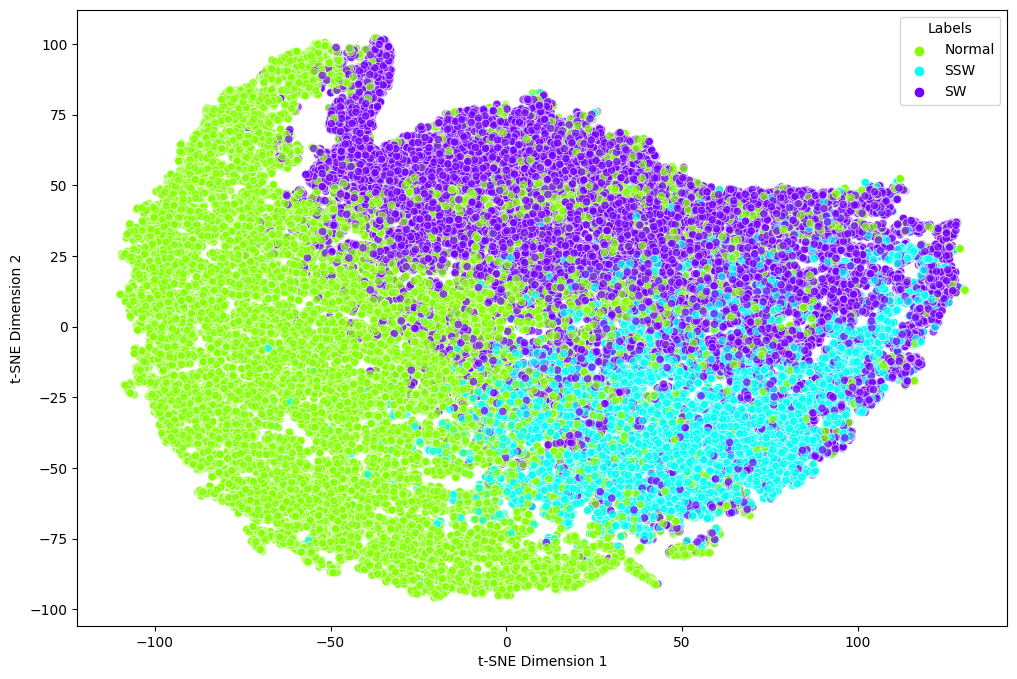

In [ ]:
# ====================================================================
# BLOCK 1: t-SNE VISUALIZATION (ALL BRANCHES + FUSED FEATURES)
# ====================================================================
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import collections
from tqdm import tqdm

# --- Step 1: Set up hooks to capture features from all sources ---
features = collections.defaultdict(list)

def create_branch_hook(key_name):
    def hook_fn(module, input, output):
        features[key_name].append(output[0].cpu().detach().numpy())
    return hook_fn

def get_fused_features_hook(module, input, output):
    features['fused_features'].append(input[0].cpu().detach().numpy())

# --- Step 2: Run a subset of data through the model to collect features ---
# try:
print("\nRunning model on a subset of test data to collect features for t-SNE...")

# Register four hooks on their respective modules
# hook_handle_raw = model.branches[0].register_forward_hook(create_branch_hook('raw_features'))
hook_handle_fft = model.branches[1].register_forward_hook(create_branch_hook('fft_features'))
hook_handle_wavelet = model.branches[2].register_forward_hook(create_branch_hook('wavelet_features'))
hook_handle_fused = model.classifier.register_forward_hook(get_fused_features_hook)

true_labels = []
samples_collected = 0

model.eval()
with torch.no_grad():
    for _, eeg_data, fft_data, wavelet_data, labels in tqdm(test_loader, desc="Collecting Features"):
        model_inputs = [
            eeg_data.squeeze(1).to(device),
            fft_data.squeeze(1).to(device),
            wavelet_data.squeeze(1).to(device)
        ]
        
        _ = model(model_inputs, active_branch_indices=active_branches)
        
        true_labels.extend(labels.cpu().numpy())
        samples_collected += eeg_data.size(0)

# CRITICAL: Remove all hooks after use
# hook_handle_raw.remove()
hook_handle_fft.remove()
hook_handle_wavelet.remove()
hook_handle_fused.remove()
print(f"\nCollected features from {samples_collected} samples.")

# --- Step 3: Run t-SNE and Visualize for all four feature sets ---
fig, axs = plt.subplots(3, 1, figsize=(10, 24))
fig.suptitle('t-SNE Visualization of Features: Branches vs. Final Fused Ensemble', fontsize=20)

feature_keys = ['fft_features', 'wavelet_features', 'fused_features']
plot_titles = ['FFT Branch', 'Wavelet Branch', 'Final Fused Features']


# except NameError as e:
#      print(f"\nSkipping t-SNE analysis because a required variable was not found: {e}")
# except Exception as e:
    # print(f"\nAn error occurred during t-SNE analysis: {e}")


Running t-SNE for: FFT Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Wavelet Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Final Fused Features...
(74774, 96)
(74774,)
t-SNE calculation complete.


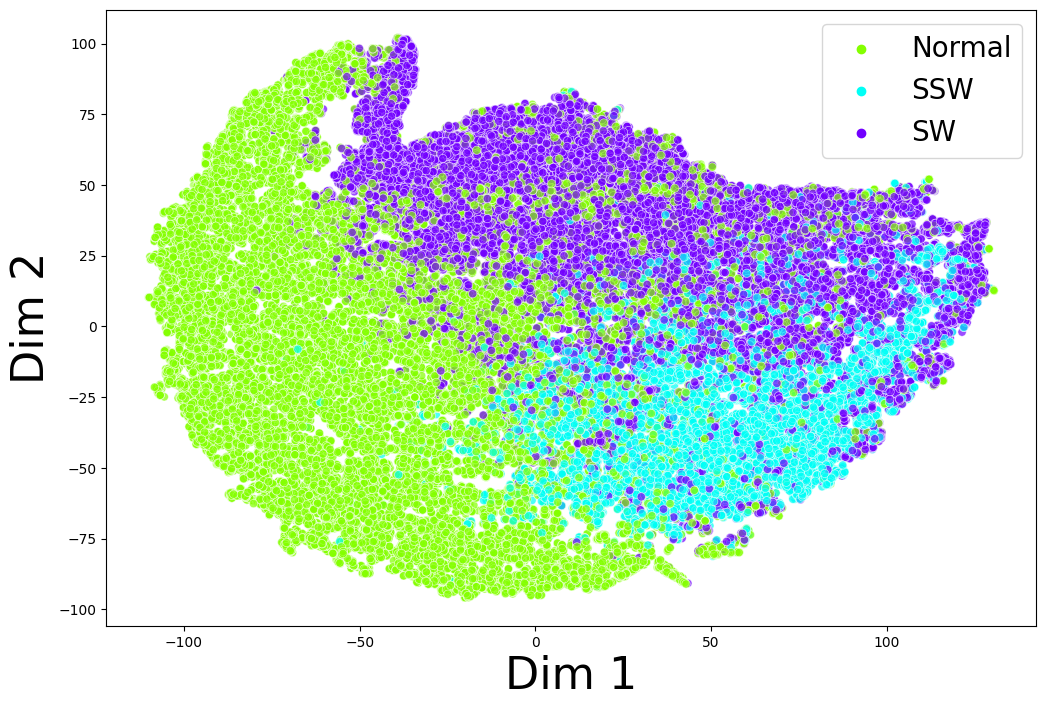

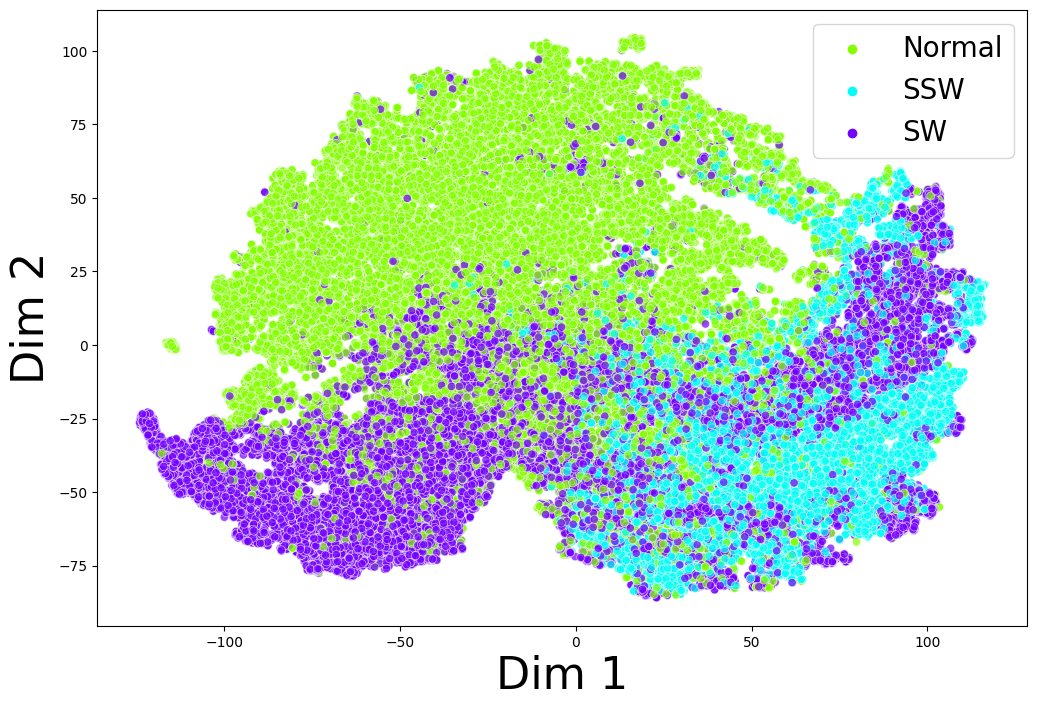

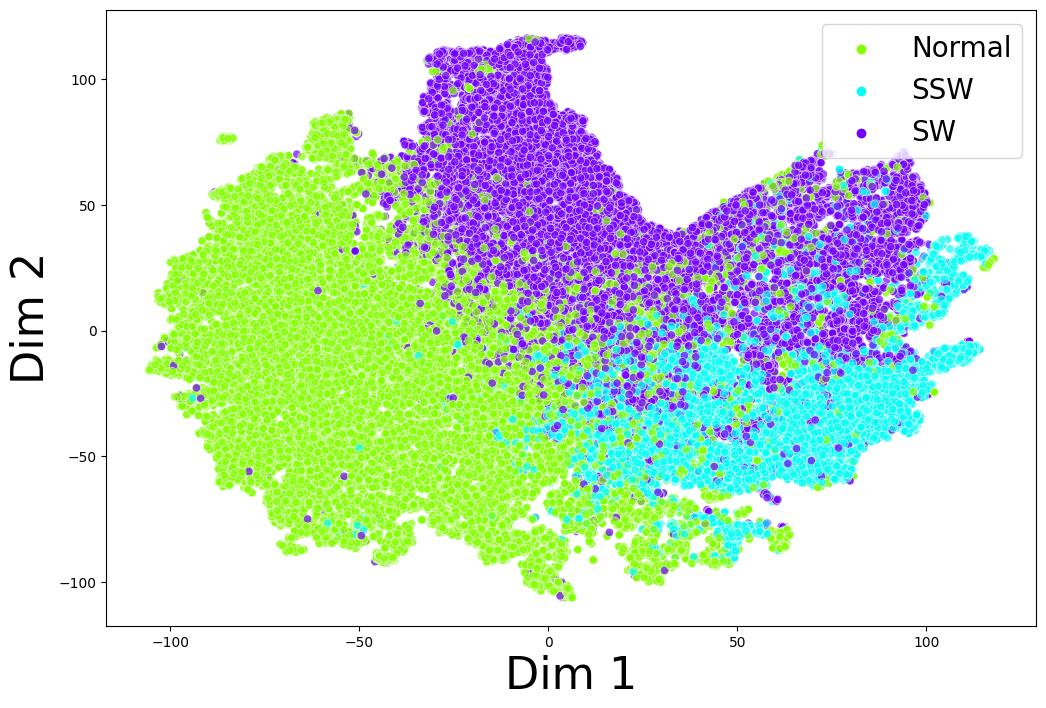

In [14]:

for ax, key, title in zip(axs, feature_keys, plot_titles):
    print(f"\nRunning t-SNE for: {title}...")
    
    features_np = np.concatenate(features[key], axis=0)
    # true_labels_np = np.array(true_labels)[:features_np.shape[0]]
    # true_labels_np = np.array(true_labels)[:features_np.shape[0]]
    true_labels_np = np.array(true_labels)
    # true_labels_np = np.repeat(true_labels, 7)
    print(features_np.shape)
    print(true_labels_np.shape)

    
    tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
    tsne_results = tsne.fit_transform(features_np)
    print("t-SNE calculation complete.")

    label_map = {
    0: 'Normal',
    1: 'SSW',  # Sharp and Spike Wave
    2: 'SW'    # Slow Wave
    }
        

    true_labels_mapped = [label_map[label] for label in true_labels_np]

    tsne_df = pd.DataFrame({
        't-SNE Dimension 1': tsne_results[:,0],
        't-SNE Dimension 2': tsne_results[:,1],
        'Labels': true_labels_mapped 
    })

    plt.figure(figsize=(12, 8))
        
    sns.scatterplot(
        x="t-SNE Dimension 1", y="t-SNE Dimension 2",
        hue="Labels", 
        hue_order=['Normal', 'SSW', 'SW'], 
        palette=sns.color_palette("hsv", n_colors=len(label_map)), 
        data=tsne_df,
        legend="full",
        alpha=0.7
    )
    plt.xlabel('Dim 1', fontsize=32)
    plt.ylabel('Dim 2', fontsize=32)

    plt.legend(fontsize=20, title=None, loc='upper right')

# plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Running model on a subset of test data to collect features for t-SNE...


  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)



Collected features from 74774 samples.
Combined features shape: (74774, 64)
Fused features shape: (74774, 96)
true_labels shape: (74774,)

Running t-SNE on combined features (74774 samples)...
t-SNE calculation for combined features complete.

Running t-SNE on fused features (74774 samples)...
t-SNE calculation for fused features complete.


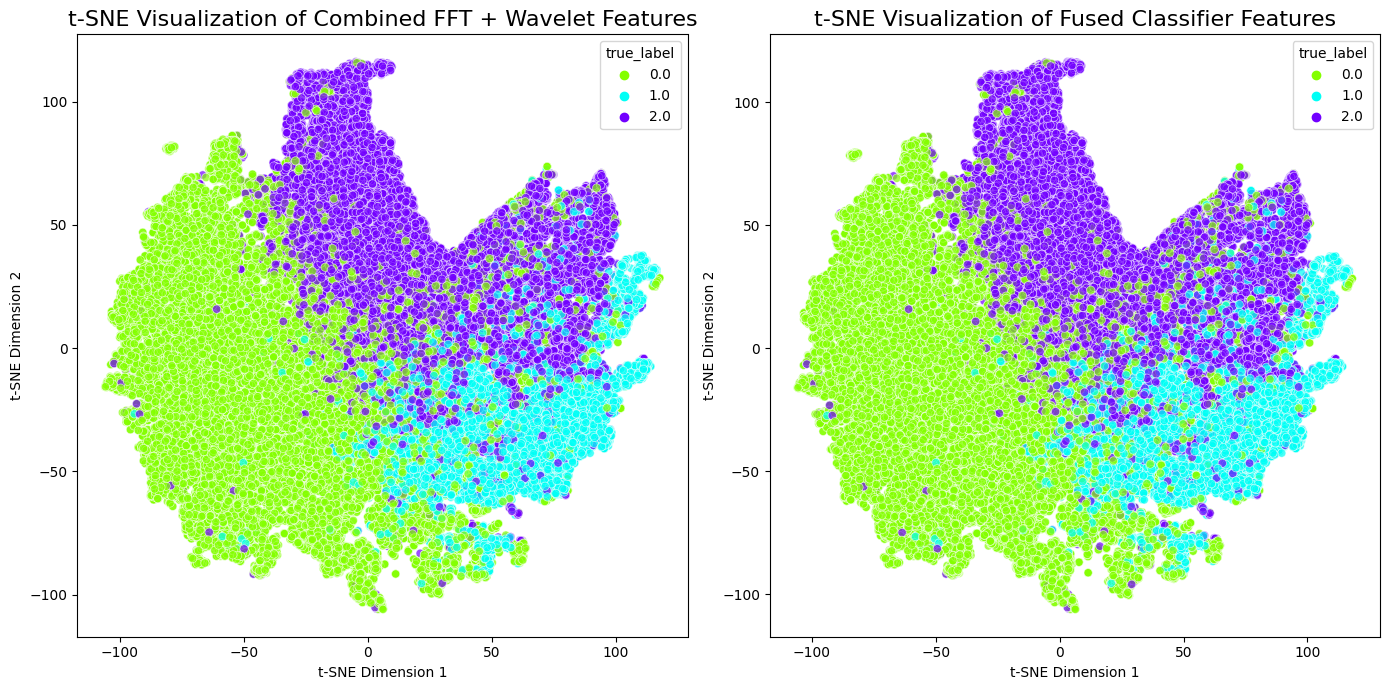

In [9]:
# ====================================================================
# BLOCK 1: t-SNE VISUALIZATION (ALL BRANCHES + FUSED FEATURES) ----> Maaz (An experiment to see the difference between 64 and 96 features)
# ====================================================================
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import collections
from tqdm import tqdm

# --- Step 1: Set up hooks to capture features from all sources ---
features = collections.defaultdict(list)

def create_branch_hook(key_name):
    def hook_fn(module, input, output):
        features[key_name].append(output[0].cpu().detach().numpy())
    return hook_fn

def get_fused_features_hook(module, input, output):
    features['fused_features'].append(input[0].cpu().detach().numpy())

# --- Step 2: Run a subset of data through the model to collect features ---
print("\nRunning model on a subset of test data to collect features for t-SNE...")

# Register hooks for each feature set (combined features, and fused features)
hook_handle_fft = model.branches[1].register_forward_hook(create_branch_hook('fft_features'))
hook_handle_wavelet = model.branches[2].register_forward_hook(create_branch_hook('wavelet_features'))
hook_handle_fused = model.classifier.register_forward_hook(get_fused_features_hook)

true_labels = []
samples_collected = 0

model.eval()
with torch.no_grad():
    for _, eeg_data, fft_data, wavelet_data, labels in tqdm(test_loader, desc="Collecting Features"):
        model_inputs = [
            eeg_data.squeeze(1).to(device),
            fft_data.squeeze(1).to(device),
            wavelet_data.squeeze(1).to(device)
        ]
        
        _ = model(model_inputs, active_branch_indices=active_branches)
        
        true_labels.extend(labels.cpu().numpy())
        samples_collected += eeg_data.size(0)

# CRITICAL: Remove all hooks after use
hook_handle_fft.remove()
hook_handle_wavelet.remove()
hook_handle_fused.remove()

print(f"\nCollected features from {samples_collected} samples.")

# --- Step 3: Format data and run t-SNE ---
# Combine FFT and Wavelet features to create a single (x, 64) feature set
fft_features_np = np.concatenate(features['fft_features'], axis=0)
wavelet_features_np = np.concatenate(features['wavelet_features'], axis=0)

combined_features = np.concatenate([fft_features_np, wavelet_features_np], axis=1)

# Get fused features
fused_features_np = np.concatenate(features['fused_features'], axis=0)

# Check the shapes of the feature sets
print(f"Combined features shape: {combined_features.shape}")
print(f"Fused features shape: {fused_features_np.shape}")

# true_labels_np = np.array(true_labels)[:features_np.shape[0]]
true_labels_np = np.array(true_labels)
print(f"true_labels shape: {true_labels_np.shape}")

# --- Step 4: Run t-SNE on both feature sets ---
# Run t-SNE for combined features (fft + wavelet)
print(f"\nRunning t-SNE on combined features ({combined_features.shape[0]} samples)...")
tsne_combined = TSNE(n_components=2, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
tsne_combined_results = tsne_combined.fit_transform(combined_features)
print("t-SNE calculation for combined features complete.")

# Run t-SNE for fused features
print(f"\nRunning t-SNE on fused features ({fused_features_np.shape[0]} samples)...")
tsne_fused = TSNE(n_components=2, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
tsne_fused_results = tsne_fused.fit_transform(fused_features_np)
print("t-SNE calculation for fused features complete.")

# --- Step 5: Visualize the results ---

# Create DataFrames for visualization
tsne_combined_df = pd.DataFrame({
    'tsne-2d-one': tsne_combined_results[:, 0],
    'tsne-2d-two': tsne_combined_results[:, 1],
    'true_label': true_labels_np
})

tsne_fused_df = pd.DataFrame({
    'tsne-2d-one': tsne_fused_results[:, 0],
    'tsne-2d-two': tsne_fused_results[:, 1],
    'true_label': true_labels_np
})

# Create subplots for both combined and fused features
plt.figure(figsize=(14, 7))

# Plot for combined features
plt.subplot(1, 2, 1)
sns.scatterplot(
    x="tsne-2d-one", y="tsne-2d-two",
    hue="true_label",
    palette=sns.color_palette("hsv", len(np.unique(true_labels_np))),
    data=tsne_combined_df,
    legend="full",
    alpha=0.7
)
plt.title('t-SNE Visualization of Combined FFT + Wavelet Features', fontsize=16)
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')

# Plot for fused features
plt.subplot(1, 2, 2)
sns.scatterplot(
    x="tsne-2d-one", y="tsne-2d-two",
    hue="true_label",
    palette=sns.color_palette("hsv", len(np.unique(true_labels_np))),
    data=tsne_fused_df,
    legend="full",
    alpha=0.7
)
plt.title('t-SNE Visualization of Fused Classifier Features', fontsize=16)
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')

# Show the plot
plt.tight_layout()
plt.show()
